> **Aktualizace, 24. října.** Nasazený model je nyní model s měřeními dělenými proudem plazmatu (`analysis/clean_model.py`, `results/clean-model.md`). Tento notebook analyzuje `cand`, předchozí nasazený model: kde se píše „nasazený“, myslí se `cand` a čísla jsou čísla `cand`. Dnešní nasazený model se hodnotí v oddílu „Nasazený model dnes“ v notebooku 09.

# 08 Robustnost a množství dat: co se stane se zašuměnými signály, driftem, méně učicími daty a několika minulými vzorky na vstupu?

**Otázka (bonusové body o šumu a driftu, množství dat a časovém kontextu).** (1) Co je v zašuměném souboru, který nám organizátoři dali,
a je v něm drift? (2) O kolik je horší síť natrénovaná na čistých datech, když je vstup zašuměný nebo driftuje, a co stojí a
přináší síť natrénovaná se šumem? (3) Kolik učicích výbojů potřebujeme? (4) Pomůže, když síť dostane posledních tři vzorky místo jednoho?

Tento notebook **nepotřebuje data**. Čísla čte z agregovaných souborů uložených v `results/`
(`data-checks.md`, `robustness-findings.md`, `final-evaluation.md`, `stability-over-time.json`, `latency.json`); nečte se žádný řádek dat ÚFP a nic se neučí,
takže proběhne od začátku do konce na čistém checkoutu za pár vteřin (potřebuje `numpy pandas matplotlib`). Měření provedly skripty v `analysis/`
na důvěrných datech; každá tabulka uvádí svůj protokol.

| název | co to je | použito pro |
|---|---|---|
| **R, 5 foldů** | základní síť (256-256-128, 60 epoch), 5 foldů dělených po celých výbojích, průměr přes foldy, 119 učicích výbojů na fold; šum a drift generujeme my, pokud se nejmenuje **dodaný zašuměný soubor** | oddíly 1, 2, 4, 5 |
| **O, mimo učicí sadu** | souhrnné predikce téhož základu mimo učicí sadu na čistých vstupech, na dodaných zašuměných vstupech a ze sítě natrénované se šumem a driftem (`stability-over-time.json`) | oddíl 3 |
| **L, odložené** | modely natrénované na 119 vývojových výbojích, hodnocené jednou pro každý konečný model na 30 odložených výbojích; jedno semínko (`final-evaluation.md`) | oddíl 2.1 |

Jednotky: mm pro polohy, kA pro proud plazmatu, elongace bez jednotky. Chyby jsou průměrné absolutní rozdíly (MAE) od referenční rekonstrukce (rekonstrukce rovnováhy ústavu, která dává štítky, ne nezávislé měření plazmatu). **Rozsah:** vše tu platí pro
*základní síť*; šum je bílý šum dodaný organizátory (drift je náš vlastní syntetický model); tvrzení o stabilitě jsou podmíněná druhem vstupu.

In [1]:
import re, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown as _Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# Tento notebook čte jen soubory uložené v results/ (tabulky, json, png); nepotřebuje data ÚFP ani žádné učení.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "final-evaluation.md").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře: results/final-evaluation.md nebyl nalezen")
RES = repo / "results"
READ = set()  # každý soubor s výsledky, který notebook otevře; na konci se zkontroluje proti `git ls-files`


def read(name):
    READ.add(name)
    return (RES / name).read_text()


def num(x):
    """První číslo v buňce: '44.2%' -> 44.2, '1.2 [0.9, 1.4]' -> 1.2, '0.53 to 1.10 (2.1x)' -> 0.53, 'n/a' -> nan."""
    m = re.search(r"-?\d+(?:\.\d+)?(?:e[+-]?\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else np.nan


def md_tables(name):
    """Všechny tabulky s rourami ze souboru markdown s výsledky jako (nejbližší nadpis nad nimi, DataFrame řetězců)."""
    out, heading, cur = [], "", None
    for line in read(name).splitlines():
        if line.startswith("#"):
            heading, cur = line.lstrip("# ").strip(), None
        elif line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if cur is None:
                cur = {"heading": heading, "header": cells, "rows": []}
                out.append(cur)
            elif not set("".join(cells)) <= set("-: "):
                cur["rows"].append(cells)
        else:
            cur = None
    return [(t["heading"], pd.DataFrame(t["rows"], columns=t["header"])) for t in out]


def table(name, heading=None, has=None, nth=0):
    """N-tá tabulka, jejíž nadpis začíná `heading` a jejíž hlavička obsahuje každý sloupec z `has`."""
    hits = [df for h, df in md_tables(name)
            if (heading is None or h.startswith(heading)) and all(c in df.columns for c in (has or []))]
    if len(hits) <= nth:
        raise KeyError(f"{name}: no table for heading={heading!r} has={has!r}")
    return hits[nth]


def numeric(df, text=("target", "unit")):
    """Index podle prvního sloupce a převod každého dalšího sloupce na float (textové sloupce zůstanou řetězce)."""
    df = df.copy()
    if "unit" in df.columns:
        df["unit"] = df["unit"].replace("", "-")  # cíle bez jednotky: soubory s výsledky nechávají buňku prázdnou
    for c in df.columns[1:]:
        if c not in text:
            df[c] = df[c].map(num).astype(float)
    return df.set_index(df.columns[0])


def section(name, heading):
    """Řádky oddílu `## heading...` (do dalšího `## `), tak jak jsou napsané v souboru s výsledky."""
    lines, on = [], False
    for line in read(name).splitlines():
        if line.startswith("## "):
            on = line[3:].startswith(heading)
            continue
        if on:
            lines.append(line)
    if not lines:
        raise KeyError(f"{name}: no section {heading!r}")
    return "\n".join(lines).strip()


def show(df, proto, fmt="{:.3g}"):
    """Vytiskne tabulku s protokolem, za kterého se měřila, těsně nad ní."""
    print("Protokol:", proto)
    print(df.to_string(float_format=lambda v: fmt.format(v)))
    print()


def cz(text):
    """České číslování v generovaném textu: desetinná čárka místo tečky, mezera jako oddělovač tisíců."""
    text = re.sub(r"(?<![\d,.])([1-9]\d{0,2}),(\d{3})\b", "\\1\u00a0\\2", text)
    return re.sub(r"(?<=\d)\.(?=\d)", ",", text)


def Markdown(text):
    """Vygenerovaný text s českými čísly (citace ze souborů s výsledky jdou přes _Markdown beze změny)."""
    return _Markdown(cz(text))


def quote(text, source):
    display(_Markdown(f"*Citováno z `results/{source}`:*\n\n" + text))


def tracked_check():
    """Seznam souborů, které nejsou pod správou gitu (a počet přečtených); každý otevřený soubor s výsledky musí být v gitu, ne jen lokální pracovní soubor."""
    out = subprocess.run(["git", "-C", str(repo), "ls-files", "results"], capture_output=True, text=True)
    tracked = {Path(p).name for p in out.stdout.split()}
    missing = sorted(f for f in READ if f not in tracked)
    return missing, len(READ), bool(tracked)


print("repozitář:", repo.name, "| složka s výsledky:", RES.relative_to(repo))

repozitář: hackathon | složka s výsledky: results


## 1. Co je v zašuměném souboru? Bílý šum, žádný drift

`equil_data_noisy.csv` je čistý soubor s přidaným šumem. `data-checks.md` měří jeho strukturu: šum dělený směrodatnou odchylkou
signálu, jeho korelaci s časem uvnitř výboje (lineární drift by se tu ukázal) a jeho autokorelaci o jeden krok (bílý šum má kolem nuly).

*Citováno z `results/data-checks.md`:*

- Noise standard deviation over the standard deviation of the signal: IPR coils median 0.158, flux loops median 0.090, overall range 0.086 to 0.167.
- Mean absolute correlation of the noise with time inside a discharge (a linear drift would show here): 0.049.
- Mean lag-1 autocorrelation of the noise inside a discharge (white noise is about 0): -0.004.
- Reading: white noise, no measurable drift; every drift result of ours is synthetic.

šum cívek 0.158 a smyček toku 0.09 sm. odchylky signálu (rozsah 0.086 až 0.167); korelace s časem 0.049; autokorelace o jeden krok -0.004 (zpráva o robustnosti uvádí asi -0.005 z druhého měření)


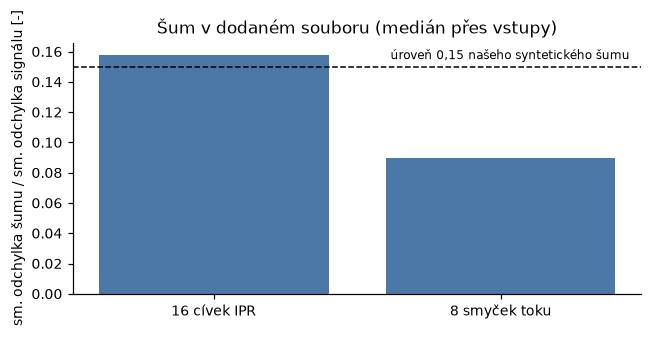

**Čtení.** Dodaný zašuměný soubor je bílý šum (autokorelace o jeden krok -0,004, tedy kolem 0) bez měřitelného driftu (průměrná absolutní korelace s časem je malá hodnota, kterou bílý šum dává, 0,049). Od čistého souboru se liší o 0,155 sm. odchylky vstupu (medián). Syntetický šum úrovně 0,15 dává stejné chyby jako dodaný soubor (radiální osa 10,4 mm proti 10,2 mm), takže dodaný soubor zastupuje. Neříká nic o šumu skutečných sond: dodaný šum vypadá jako šum přidaný úměrně směrodatné odchylce každého vstupu (poměr zůstává mezi 0,086 a 0,167; náš závěr, nepotvrzený) a může být větší než šum skutečných sond (ověřit s ústavem), takže tyto chyby jsou zátěžový test, ne očekávaný provozní výkon. **Každý výsledek o driftu níže je syntetický**: drift našeho vlastního návrhu, ne změřený drift skutečné diagnostiky.

In [2]:
F_CHK, F_ROB = "data-checks.md", "robustness-findings.md"
noise_txt = section(F_CHK, "Structure of the noise")
quote(noise_txt, F_CHK)
m = re.search(r"IPR coils median (\d+\.\d+), flux loops median (\d+\.\d+), overall range (\d+\.\d+) to (\d+\.\d+)", noise_txt)
coil_med, fl_med, lo, hi = map(float, m.groups())
corr_time = float(re.search(r"correlation of the noise with time.*?: (-?\d+\.\d+)\.", noise_txt).group(1))
lag1 = float(re.search(r"lag-1 autocorrelation.*?: (-?\d+\.\d+)\.", noise_txt).group(1))
rob = read(F_ROB)
lag1_rob = float(re.search(r"lag 1 autocorrelation of\s+the noise about (-?\d+\.\d+)", rob).group(1))
diff_med = float(re.search(r"differs\s+from the clean one by (\d+\.\d+) of an input SD", rob).group(1))
syn, prov = map(float, re.search(r"R axis (\d+\.\d+) mm\s+synthetic against (\d+\.\d+) mm provided", rob).groups())
print(f"šum cívek {coil_med} a smyček toku {fl_med} sm. odchylky signálu (rozsah {lo} až {hi}); korelace s časem {corr_time}; autokorelace o jeden krok {lag1} "
      f"(zpráva o robustnosti uvádí asi {lag1_rob} z druhého měření)")

fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(["16 cívek IPR", "8 smyček toku"], [coil_med, fl_med], color="#4c78a8")
ax.axhline(0.15, color="k", ls="--", lw=1); ax.text(1.45, 0.155, "úroveň 0,15 našeho syntetického šumu", ha="right", fontsize=8)
ax.set_ylabel("sm. odchylka šumu / sm. odchylka signálu [-]"); ax.set_title("Šum v dodaném souboru (medián přes vstupy)"); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Čtení.** Dodaný zašuměný soubor je bílý šum (autokorelace o jeden krok {lag1}, tedy kolem 0) bez měřitelného driftu (průměrná absolutní korelace s časem je malá hodnota, kterou bílý šum dává, "
    f"{corr_time:.3f}). Od čistého souboru se liší o {diff_med} sm. odchylky vstupu (medián). "
    f"Syntetický šum úrovně 0,15 dává stejné chyby jako dodaný soubor (radiální osa {syn} mm proti {prov} mm), takže dodaný soubor zastupuje. "
    f"Neříká nic o šumu skutečných sond: dodaný šum vypadá jako šum přidaný úměrně směrodatné odchylce každého vstupu (poměr zůstává mezi {lo} a {hi}; náš závěr, nepotvrzený) "
    f"a může být větší než šum skutečných sond (ověřit s ústavem), takže tyto chyby jsou zátěžový test, ne očekávaný provozní výkon. "
    f"**Každý výsledek o driftu níže je syntetický**: drift našeho vlastního návrhu, ne změřený drift skutečné diagnostiky."))

## 2. Šum a drift: učeno na čistých, učeno na zašuměných, učeno s augmentací (protokol R, 5 foldů)

Syntetický šum je gaussovský, na řádek, se směrodatnou odchylkou danou zlomkem učicí směrodatné odchylky každého vstupu. Drift je `c * t`: nezávislý gaussovský
sklon pro každý výboj a cívku (`c` je směrodatná odchylka sklonu), `t` relativní čas výboje; běhy s driftem přidávají také šum 0,15.
*Augmentované* znamená učené na čistých řádcích plus jedné poškozené kopii (šum 0,15, drift 0,15).

Každý výboj dosáhne na konci stejného celkového driftu bez ohledu na délku; skutečný posun integrátoru roste s absolutním časem. Chyby kalibrace, selhání nebo saturace sondy, rušení od proudů v cívkách a tepelný drift se netestovaly.

Protokol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`robustness-findings.md`)
                                                             R axis [mm]  Z axis [mm]  elongation [-]  limiter Z [mm]  is_limited accuracy [%]
trained on, tested on                                                                                                                         
clean, clean                                                        0.38         0.39          0.0057            22.2                     99.3
clean, provided noisy                                               10.2         4.12           0.032            62.6                     98.6
clean, synthetic noise 0.30                                         20.8          8.5           0.069             110                     95.7
clean, synthetic noise 0.15 + synthetic drift 0.30                  15.1         

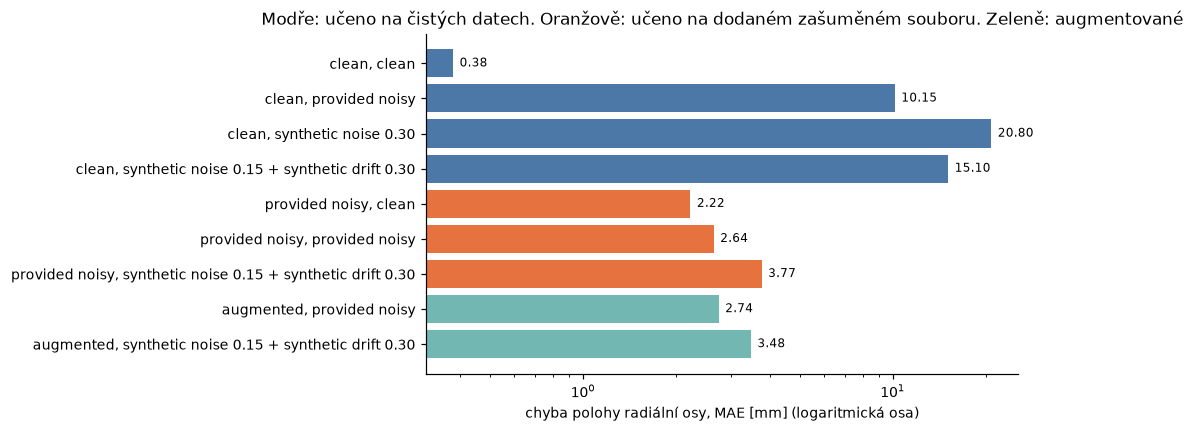

In [3]:
P_R = ("R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; "
       "noise and drift synthetic unless 'provided noisy' (`robustness-findings.md`)")
nd = numeric(table(F_ROB, "1. Noise and drift"), text=())
nd.index.name = "trained on, tested on"
def synth(s):  # ať je jasné, že drift (a přidaný šum) jsou naše, ne v dodaném souboru
    return s.replace("noise 0.", "synthetic noise 0.").replace("drift 0.", "synthetic drift 0.")


nd.columns = ["R axis [mm]", "Z axis [mm]", "elongation [-]", "limiter Z [mm]", "is_limited accuracy [%]"]
show(nd.rename(index=synth), P_R)

fig, ax = plt.subplots(figsize=(9.5, 4)); names = list(nd.index)
colors = ["#4c78a8" if n.startswith("clean") else "#e6733f" if n.startswith("provided") else "#72b7b2" for n in names]
ax.barh([synth(n) for n in names], nd["R axis [mm]"], color=colors); ax.set_xscale("log"); ax.invert_yaxis()
for i, v in enumerate(nd["R axis [mm]"]): ax.text(v * 1.05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("chyba polohy radiální osy, MAE [mm] (logaritmická osa)")
ax.set_title("Modře: učeno na čistých datech. Oranžově: učeno na dodaném zašuměném souboru. Zeleně: augmentované")
plt.tight_layout(); plt.show()

In [4]:
cc, cn = nd.loc["clean, clean", "R axis [mm]"], nd.loc["clean, provided noisy", "R axis [mm]"]
nn, nc = nd.loc["provided noisy, provided noisy", "R axis [mm]"], nd.loc["provided noisy, clean", "R axis [mm]"]
drift_h = nd.loc["provided noisy, noise 0.15 + drift 0.30", "R axis [mm]"] - nn
drift_c = nd.loc["clean, noise 0.15 + drift 0.30", "R axis [mm]"] - syn
display(Markdown(
    f"**Čtení (radiální osa, mm).** Síť učená na čistých datech se s referenční rekonstrukcí shoduje těsně a je křehká: {cc:.2f} na čistých vstupech, **{cn:.1f}** na dodaných zašuměných vstupech ({cn/cc:.0f}krát víc). "
    f"Učená na zašuměném souboru dává **{nn:.2f}** na zašuměných vstupech, ale {nc:.2f} na čistých: robustnost se platí horší shodou na čistých vstupech. "
    f"Syntetický drift se sm. odchylkou sklonu 0,3 navíc k šumu 0,15 přidá {drift_h:.1f} mm síti učené na zašuměném souboru a {drift_c:.1f} mm síti učené na čistých datech "
    f"(samotný šum 0,15 tam dává {syn} mm, `{F_ROB}`). Amplitudy driftu a šumu nejsou srovnatelné, takže neříkáme, že drift škodí méně než šum. "
    f"Naše augmentace není lepší než učení na dodaném zašuměném souboru ({nd.loc['augmented, provided noisy','R axis [mm]']:.2f} proti {nn:.2f} mm, rozdíl, který zpráva nepovažuje za prokázaný); "
    f"její smysl je, že nepotřebuje zašuměný soubor."))

**Čtení (radiální osa, mm).** Síť učená na čistých datech se s referenční rekonstrukcí shoduje těsně a je křehká: 0,38 na čistých vstupech, **10,2** na dodaných zašuměných vstupech (27krát víc). Učená na zašuměném souboru dává **2,64** na zašuměných vstupech, ale 2,22 na čistých: robustnost se platí horší shodou na čistých vstupech. Syntetický drift se sm. odchylkou sklonu 0,3 navíc k šumu 0,15 přidá 1,1 mm síti učené na zašuměném souboru a 4,7 mm síti učené na čistých datech (samotný šum 0,15 tam dává 10,4 mm, `robustness-findings.md`). Amplitudy driftu a šumu nejsou srovnatelné, takže neříkáme, že drift škodí méně než šum. Naše augmentace není lepší než učení na dodaném zašuměném souboru (2,74 proti 2,64 mm, rozdíl, který zpráva nepovažuje za prokázaný); její smysl je, že nepotřebuje zašuměný soubor.

### 2.1 Táž výměna na 30 odložených výbojích (protokol L)

`final-evaluation.md` porovnává obyčejný základ, základ natrénovaný se šumem a driftem (`augmented`) a nasazenou recepturu kandidáta (diferenční vstupy, ridge proud, síť pro limiter spouštěná podmínkou),
každý na čistých vstupech a na dodaném zašuměném souboru. Sada 30 výbojů je **snazší než vývojový průměr** (viz notebook 07, oddíl 4.1), takže tato
čísla jsou nižší než ta z křížové validace výše a nedají se s nimi srovnávat.

Protokol: L: trained on 119 development discharges, scored on 30 kept-aside discharges (8,761 rows), one seed (`final-evaluation.md`); MAE kromě posledního sloupce
                                      plasma_current [kA]  R_mag_axis [mm]  Z_mag_axis [mm]  R_x_point [mm]  R_limiter [mm]  mean nRMSE (16)
recipe                        inputs                                                                                                        
baseline MLP                  clean                   1.2            0.307            0.321           0.161            10.6           0.0803
                              noisy                  5.63             9.16             3.82            4.35            48.9           0.4923
baseline, noise-trained       clean                  1.91             1.56            0.837            1.56            18.6           0.1998
                              noisy                  4.65             2.38             1.86            2.47            25.8        

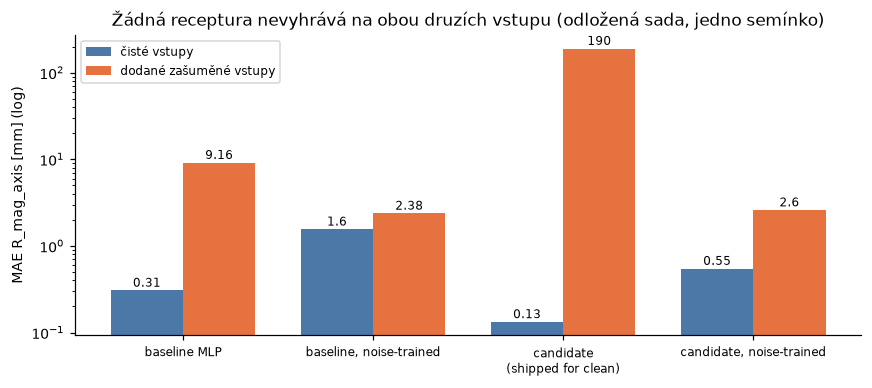

*Citováno z `results/final-evaluation.md`:*

- **clean inputs: candidate, plain** (`cand`): lowest mean nRMSE over the 16 targets in the development cross-validation (baseline MLP 0.1228, baseline MLP, augmented (extra) 0.2385, candidate, plain 0.0912, candidate, augmented 0.1705).
- **noisy inputs: baseline MLP, augmented (extra)** (`base_aug`): lowest mean nRMSE over the 16 targets in the development cross-validation (baseline MLP 0.5267, baseline MLP, augmented (extra) 0.3129, candidate, plain 12.4320, candidate, augmented 0.3321).
- Check on the locked test set of that choice: mean nRMSE over 16 targets, clean: baseline MLP 0.0803, baseline MLP, augmented (extra) 0.1998, candidate, plain 0.0590, candidate, augmented 0.1108; noisy: baseline MLP 0.4923, baseline MLP, augmented (extra) 0.2891, candidate, plain 12.0304, candidate, augmented 0.3159.

**Čtení.** Na zašuměných vstupech dává základ učený se šumem 2,38 mm na radiální ose proti 9,16 mm u obyčejného základu; obyčejný kandidát se zhroutí (190 mm, průměrné nRMSE 12,0), protože jeho rozdíly sousedních cívek šum zesilují. Na čistých vstupech je základ učený se šumem 5,1krát horší než obyčejný základ. Nasazení proto musí vědět, jaký druh vstupu dostane; jeden model, který vyhrává v obou případech, neexistuje.

In [5]:
F_FIN = "final-evaluation.md"
P_L = "L: trained on 119 development discharges, scored on 30 kept-aside discharges (8,761 rows), one seed (`final-evaluation.md`)"
recipes = {"baseline MLP": "baseline MLP", "baseline MLP, augmented (extra)": "baseline, noise-trained", "candidate, plain": "candidate (shipped for clean)", "candidate, augmented": "candidate, noise-trained"}
tg = ["plasma_current", "R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter"]
res = {}
for key, short in recipes.items():
    for kind in ("clean", "noisy"):
        d = numeric(table(F_FIN, f"{key}, {kind} inputs"))
        head = [h for h, _ in md_tables(F_FIN) if h.startswith(f"{key}, {kind} inputs")][0]
        res[(short, kind)] = {t: d.loc[t, "MAE"] for t in tg} | {"mean nRMSE (16)": float(re.search(r"mean nRMSE over 16 targets (\d+\.\d+)", head).group(1))}
lock = pd.DataFrame(res).T
lock.index.names = ["recipe", "inputs"]
lock.columns = ["plasma_current [kA]", "R_mag_axis [mm]", "Z_mag_axis [mm]", "R_x_point [mm]", "R_limiter [mm]", "mean nRMSE (16)"]
show(lock, P_L + "; MAE kromě posledního sloupce", fmt="{:.4g}")

fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(recipes)); w = 0.38
vals_c = [lock.loc[(r, "clean"), "R_mag_axis [mm]"] for r in recipes.values()]; vals_n = [lock.loc[(r, "noisy"), "R_mag_axis [mm]"] for r in recipes.values()]
ax.bar(x - w/2, vals_c, w, label="čisté vstupy", color="#4c78a8"); ax.bar(x + w/2, vals_n, w, label="dodané zašuměné vstupy", color="#e6733f")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([r.replace(" (", "\n(") for r in recipes.values()], fontsize=8)
for xi, v in zip(x - w/2, vals_c): ax.text(xi, v * 1.1, f"{v:.2g}", ha="center", fontsize=8)
for xi, v in zip(x + w/2, vals_n): ax.text(xi, v * 1.1, f"{v:.3g}", ha="center", fontsize=8)
ax.set_ylabel("MAE R_mag_axis [mm] (log)"); ax.set_title("Žádná receptura nevyhrává na obou druzích vstupu (odložená sada, jedno semínko)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

quote(section(F_FIN, "Which recipe to ship").replace("Locked-set check", "Check on the locked test set"), F_FIN)   # název protokolu, jako v tomto notebooku
b, ba, cp = lock.loc[("baseline MLP", "noisy"), "R_mag_axis [mm]"], lock.loc[("baseline, noise-trained", "noisy"), "R_mag_axis [mm]"], lock.loc[("candidate (shipped for clean)", "noisy"), "R_mag_axis [mm]"]
display(Markdown(
    f"**Čtení.** Na zašuměných vstupech dává základ učený se šumem {ba:.2f} mm na radiální ose proti {b:.2f} mm u obyčejného základu; obyčejný kandidát se zhroutí ({cp:.0f} mm, "
    f"průměrné nRMSE {lock.loc[('candidate (shipped for clean)','noisy'),'mean nRMSE (16)']:.1f}), protože jeho rozdíly sousedních cívek šum zesilují. "
    f"Na čistých vstupech je základ učený se šumem {lock.loc[('baseline, noise-trained','clean'),'R_mag_axis [mm]']/lock.loc[('baseline MLP','clean'),'R_mag_axis [mm]']:.1f}krát horší než obyčejný základ. "
    f"Nasazení proto musí vědět, jaký druh vstupu dostane; jeden model, který vyhrává v obou případech, neexistuje."))

## 3. Stabilita v čase podle druhu vstupu (protokol O)

`stability-over-time.json` obsahuje míry stability predikcí mimo učicí sadu. **Poměr chvění** je RMS změny predikce z řádku na řádek dělené stejnou veličinou pro referenční hodnoty.
Je vážený amplitudou: zůstává blízko 1, kdykoli je výstup hladký proto, že je hladký jeho vstup, takže je to tvrzení o čistých vstupech a **ne** míra šumu.
Tři sloupce níže jsou obyčejná síť na čistých vstupech, obyčejná síť na dodaných zašuměných vstupech a síť natrénovaná se šumem a driftem (ve zprávě „hardened“) na zašuměných vstupech.

Protokol: O: baseline network, out-of-fold over 149 discharges; hardened = trained with noise 0.15 and drift 0.15 (`stability-over-time.json`, `stability-over-time.md`); poměr chvění = RMS změny odhadu z řádku na řádek / referenčních hodnot
                clean inputs, trained clean  noisy inputs, trained clean  noisy inputs, trained with noise and drift
R_mag_axis                             0.97                         8.42                                        1.71
Z_mag_axis                             1.06                         3.25                                        1.65
elongation                             1.03                         4.42                                        2.45
plasma_current                         1.07                         4.47                                        3.27
R_x_point                              1.00                        17.84                                        6.76



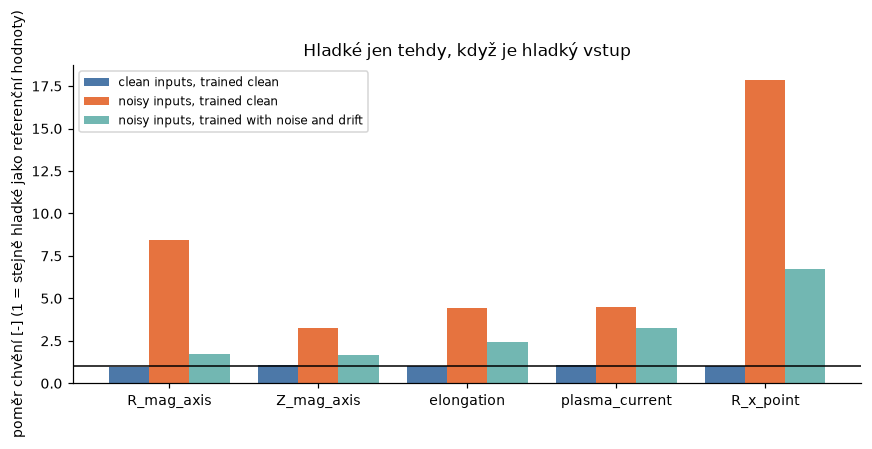

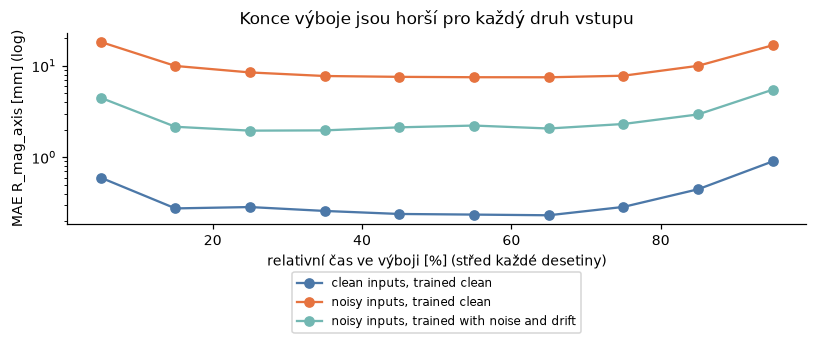

**Čtení (podmíněné).** Na čistých vstupech se výstup mění tak jako referenční hodnoty: poměr chvění 0,97 až 1,07 pro 5 zobrazených cílů. To není tvrzení o zašuměných signálech: s dodanými zašuměnými vstupy se síť učená na čistých datech mění 8,4krát (radiální osa) a 3,3krát (svislá osa) víc než referenční hodnoty a 1,71 a 1,65krát po učení se šumem a driftem.

In [6]:
tj = json.loads(read("stability-over-time.json"))
P_O = ("O: baseline network, out-of-fold over 149 discharges; hardened = trained with noise 0.15 and drift 0.15 (`stability-over-time.json`, `stability-over-time.md`)")
tt = ["R_mag_axis", "Z_mag_axis", "elongation", "plasma_current", "R_x_point"]
jit = pd.DataFrame({
    "clean inputs, trained clean": {t: tj["jitter_ratio"][t] for t in tt},
    "noisy inputs, trained clean": {t: tj["noisy"]["clean_on_noisy"]["jitter_ratio"][t] for t in tt},
    "noisy inputs, trained with noise and drift": {t: tj["noisy"]["hardened_on_noisy"]["jitter_ratio"][t] for t in tt}})
show(jit, P_O + "; poměr chvění = RMS změny odhadu z řádku na řádek / referenčních hodnot", fmt="{:.2f}")
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(jit)); w = 0.27
for i, (c, colr) in enumerate(zip(jit.columns, ["#4c78a8", "#e6733f", "#72b7b2"])): ax.bar(x + (i - 1) * w, jit[c], w, label=c, color=colr)
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(jit.index); ax.set_ylabel("poměr chvění [-] (1 = stejně hladké jako referenční hodnoty)")
ax.set_title("Hladké jen tehdy, když je hladký vstup"); ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

dec = {k: np.array(v["mae_by_time_decile"]["R_mag_axis"]) for k, v in {"clean inputs, trained clean": tj, "noisy inputs, trained clean": tj["noisy"]["clean_on_noisy"], "noisy inputs, trained with noise and drift": tj["noisy"]["hardened_on_noisy"]}.items()}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (k, v), colr in zip(dec.items(), ["#4c78a8", "#e6733f", "#72b7b2"]): ax.plot(np.arange(1, 11) * 10 - 5, v, marker="o", label=k, color=colr)
ax.set_yscale("log"); ax.set_xlabel("relativní čas ve výboji [%] (střed každé desetiny)"); ax.set_ylabel("MAE R_mag_axis [mm] (log)")
ax.set_title("Konce výboje jsou horší pro každý druh vstupu"); ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Čtení (podmíněné).** Na čistých vstupech se výstup mění tak jako referenční hodnoty: poměr chvění {jit.iloc[:,0].min():.2f} až {jit.iloc[:,0].max():.2f} pro {len(tt)} zobrazených cílů. "
    f"To není tvrzení o zašuměných signálech: s dodanými zašuměnými vstupy se síť učená na čistých datech mění {jit.loc['R_mag_axis'].iloc[1]:.1f}krát (radiální osa) a "
    f"{jit.loc['Z_mag_axis'].iloc[1]:.1f}krát (svislá osa) víc než referenční hodnoty a {jit.loc['R_mag_axis'].iloc[2]:.2f} a {jit.loc['Z_mag_axis'].iloc[2]:.2f}krát po učení se šumem a driftem."))

## 4. Množství učicích dat (protokol R, 5 foldů)

Vnořené podmnožiny učicích výbojů (v průměru 6, 12, 30, 60 a 119 výbojů; 1,7 tisíce až 34 tisíc řádků), stejné testovací foldy. **Počet epoch je pevný, 60**, takže
menší sady dostanou i méně kroků optimalizace: část zlepšení s více daty jsou kroky učení navíc a sklon je přehnaný.

Protokol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`robustness-findings.md`); testovací foldy stejné pro každý řádek, pevných 60 epoch
                     R axis [mm]  Z axis [mm]  X point R [mm]  elongation [-]  limiter Z [mm]  is_limited accuracy [%]
training discharges                                                                                                   
6                            7.3          4.7             3.9           0.145            73.7                     94.9
12                           6.9          2.8             1.5           0.075            55.6                     96.8
30                          1.47         0.95            0.75          0.0116            34.3                     98.9
60                          0.83          0.6            0.38          0.0086            28.8                     99.1
119                     

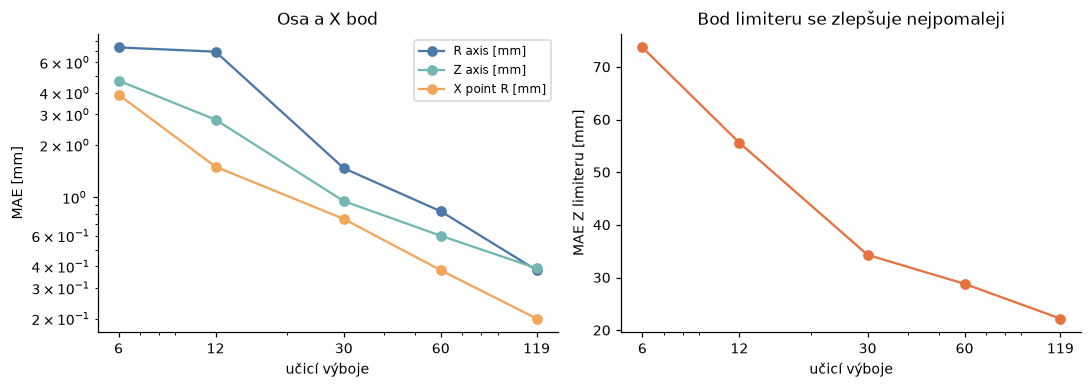

**Čtení.** Se 30 učicími výboji je chyba radiální osy 1,47 mm a svislé 0,95 mm; se všemi 119 je 0,38 a 0,39 mm. Od 30 do 119 výbojů klesne radiální chyba na 0,56 své hodnoty při prvním zdvojení a na 0,46 při druhém, zhruba na polovinu na zdvojení, ale s pevnými 60 epochami, takže je sklon přehnaný. Pod 30 výbojů je chyba několik milimetrů (7,3 mm při 6, 6,9 mm při 12 výbojích). Z limiteru se zlepšuje nejpomaleji (34, 29, 22 mm). Křivka v testovaném rozsahu nevykazuje plošinu, ale za 119 výbojů se neprodlužovala, takže nemůžeme říct, kolik by pomohlo dalších dat.

In [7]:
lc = numeric(table(F_ROB, "2. Amount of training data"), text=())
lc.index = lc.index.astype(int); lc.index.name = "training discharges"
lc.columns = ["R axis [mm]", "Z axis [mm]", "X point R [mm]", "elongation [-]", "limiter Z [mm]", "is_limited accuracy [%]"]
show(lc, P_R + "; testovací foldy stejné pro každý řádek, pevných 60 epoch")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for c, colr in zip(["R axis [mm]", "Z axis [mm]", "X point R [mm]"], ["#4c78a8", "#72b7b2", "#f2a65a"]): axes[0].plot(lc.index, lc[c], marker="o", label=c, color=colr)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("učicí výboje"); axes[0].set_ylabel("MAE [mm]"); axes[0].set_title("Osa a X bod"); axes[0].legend(fontsize=8)
axes[1].plot(lc.index, lc["limiter Z [mm]"], marker="o", color="#e6733f"); axes[1].set_xscale("log"); axes[1].set_xlabel("učicí výboje"); axes[1].set_ylabel("MAE Z limiteru [mm]"); axes[1].set_title("Bod limiteru se zlepšuje nejpomaleji")
for ax in axes: ax.set_xticks(lc.index); ax.set_xticklabels(lc.index)
plt.tight_layout(); plt.show()

r = lc["R axis [mm]"]
display(Markdown(
    f"**Čtení.** Se 30 učicími výboji je chyba radiální osy {r[30]:.2f} mm a svislé {lc.loc[30,'Z axis [mm]']:.2f} mm; se všemi {lc.index[-1]} je {r[119]:.2f} a {lc.loc[119,'Z axis [mm]']:.2f} mm. "
    f"Od 30 do 119 výbojů klesne radiální chyba na {r[60]/r[30]:.2f} své hodnoty při prvním zdvojení a na {r[119]/r[60]:.2f} při druhém, zhruba na polovinu na zdvojení, ale s pevnými 60 epochami, takže je sklon přehnaný. "
    f"Pod 30 výbojů je chyba několik milimetrů ({r[6]:.1f} mm při 6, {r[12]:.1f} mm při 12 výbojích). Z limiteru se zlepšuje nejpomaleji ({lc.loc[30,'limiter Z [mm]']:.0f}, {lc.loc[60,'limiter Z [mm]']:.0f}, {lc.loc[119,'limiter Z [mm]']:.0f} mm). "
    f"Křivka v testovaném rozsahu nevykazuje plošinu, ale za 119 výbojů se neprodlužovala, takže nemůžeme říct, kolik by pomohlo dalších dat."))

### 4.1 Menší učicí sada se objevuje i v blokovém dělení

`final-evaluation.md` se učí na 60 nejnižších číslech vývojových výbojů a testuje na 59 nejvyšších (čísla zřejmě sledují čas; organizátoři nepotvrdili). Rozdíl proti náhodným skupinovým foldům míchá
vliv výbojů s vyššími čísly (možná pozdějších kampaní) s vlivem menší učicí sady (60 proti asi 95 výbojům); pokus je neodděluje.

In [8]:
blk = [df for h, df in md_tables(F_FIN) if h.startswith("baseline MLP (60 training, 59 test discharges")][0]
blk = blk[blk["inputs"] == "clean"].set_index("target")
blk = blk.loc[["R_mag_axis", "Z_mag_axis", "R_x_point", "R_limiter"], ["unit", "blocked MAE", "random folds, same discharges MAE", "ratio"]]
blk[["blocked MAE", "random folds, same discharges MAE", "ratio"]] = blk[["blocked MAE", "random folds, same discharges MAE", "ratio"]].astype(float)
show(blk, "základní MLP, čisté vstupy, vývojová sada: blokové dělení podle čísla výboje (učí 60 nejnižších, testuje 59 nejvyšších) proti náhodným skupinovým foldům na týchž 59 výbojích (`final-evaluation.md`)")
display(Markdown(f"**Čtení.** Při blokovém dělení je chyba radiální osy {blk.loc['R_mag_axis','ratio']:.1f}krát větší než u náhodných foldů na týchž výbojích ({blk.loc['R_mag_axis','blocked MAE']:.2f} proti "
                 f"{blk.loc['R_mag_axis','random folds, same discharges MAE']:.2f} mm). Část z toho dělá menší učicí sada, takže to přeceňuje vliv samotných výbojů s vyššími čísly a obojí neodděluje."))

Protokol: základní MLP, čisté vstupy, vývojová sada: blokové dělení podle čísla výboje (učí 60 nejnižších, testuje 59 nejvyšších) proti náhodným skupinovým foldům na týchž 59 výbojích (`final-evaluation.md`)
           unit  blocked MAE  random folds, same discharges MAE  ratio
target                                                                
R_mag_axis   mm         1.23                              0.448   2.75
Z_mag_axis   mm         0.82                              0.405   2.02
R_x_point    mm        0.634                              0.219   2.89
R_limiter    mm         18.6                               11.3   1.64



**Čtení.** Při blokovém dělení je chyba radiální osy 2,8krát větší než u náhodných foldů na týchž výbojích (1,23 proti 0,45 mm). Část z toho dělá menší učicí sada, takže to přeceňuje vliv samotných výbojů s vyššími čísly a obojí neodděluje.

## 5. Časový kontext: poslední tři vzorky na vstupu (protokol R, 5 foldů)

Vstupy z řádků t-2, t-1 a t téhož výboje (kauzálně, první řádek se na začátku opakuje): 72 místo 24 vstupů. „Skok chyby“ (error step) je průměrná absolutní změna
chyby predikce mezi po sobě jdoucími vzorky, takže zachytí chvění i zpoždění a konstantní predikce nemůže vyhrát tím, že je hladká. Okno 3 řádků je délka ve vzorcích, ne v milisekundách.

Protokol: R: baseline network 256-256-128, 60 epochs, 5 folds split by discharge, MAE on held-out discharges, mean over folds; noise and drift synthetic unless 'provided noisy' (`robustness-findings.md`); okno = počet po sobě jdoucích řádků podaných síti
                       R axis [mm]  Z axis [mm]  limiter Z [mm]  error step R axis [mm]
input          window                                                                  
clean          1             0.377        0.392            22.2                   0.102
               3             0.575        0.493            19.5                   0.265
provided noisy 1              2.64         2.01            37.6                    1.84
               3              2.33         1.51            30.4                    1.15



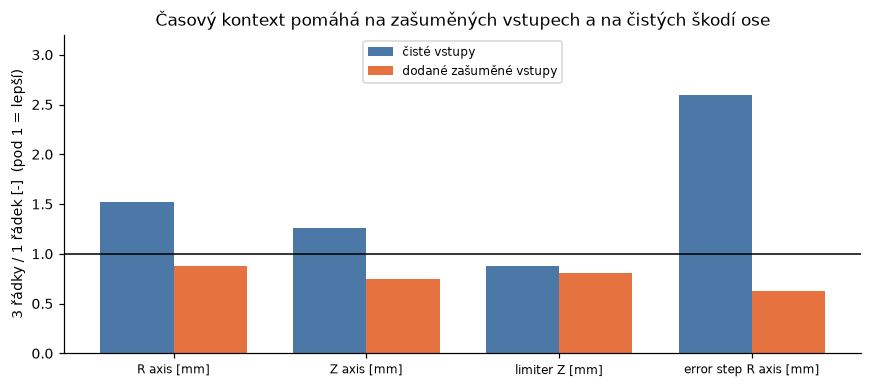

**Čtení.** S zašuměnými vstupy tři řádky snižují chybu radiální osy z 2,64 na 2,33 mm, svislou z 2,01 na 1,51 mm a skok chyby z 1,84 to 1,15 mm: historie šum vyprůměruje. S čistými vstupy stejné okno zhorší osu (0,38 na 0,57 mm) a pomůže jen Z limiteru (22,2 na 19,5 mm). Důvod není zjištěn: přeučení většího vstupního prostoru a kolineární naskládané řádky jsou dvě netestované hypotézy. Okno potřebuje jen minulé vzorky, ale síť o 72 vstupech **nebyla změřena**.

*Citováno z `results/robustness-findings.md`:*

- One initialization and one noise realization per fold; the fold to fold SD is descriptive, not a confidence interval.
  Differences of a few percent (for example augmented against noisy training) are not established.
- Drift is a model of ours (linear per coil), not a measured drift of the real diagnostics. Amplitudes were fixed before the
  run and were not tuned on test data.
- Dropped inputs, a bigger network or tuned epochs were not tried here; numbers are for the baseline architecture.
- Epochs are fixed (60, augmented 30 on twice the rows), so the learning curve mixes less information with fewer updates.

In [9]:
tc = table(F_ROB, "3. Time context")
tc.columns = ["input", "window", "R axis [mm]", "Z axis [mm]", "limiter Z [mm]", "error step R axis [mm]"]
tc["window"] = tc["window"].map(num).astype(int); tc = tc.set_index(["input", "window"]).astype(float)
show(tc, P_R + "; okno = počet po sobě jdoucích řádků podaných síti")

rel = pd.concat({k: tc.loc[(k, 3)] / tc.loc[(k, 1)] for k in ("clean", "provided noisy")}, axis=1)
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(rel)); w = 0.38
ax.bar(x - w/2, rel["clean"], w, label="čisté vstupy", color="#4c78a8"); ax.bar(x + w/2, rel["provided noisy"], w, label="dodané zašuměné vstupy", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(rel.index, fontsize=8); ax.set_ylabel("3 řádky / 1 řádek [-]  (pod 1 = lepší)")
ax.set_ylim(0, 3.2); ax.set_title("Časový kontext pomáhá na zašuměných vstupech a na čistých škodí ose"); ax.legend(fontsize=8, loc="upper center"); plt.tight_layout(); plt.show()
display(Markdown(
    f"**Čtení.** S zašuměnými vstupy tři řádky snižují chybu radiální osy z {tc.loc[('provided noisy',1),'R axis [mm]']:.2f} na {tc.loc[('provided noisy',3),'R axis [mm]']:.2f} mm, svislou z "
    f"{tc.loc[('provided noisy',1),'Z axis [mm]']:.2f} na {tc.loc[('provided noisy',3),'Z axis [mm]']:.2f} mm a skok chyby z {tc.loc[('provided noisy',1),'error step R axis [mm]']:.2f} to "
    f"{tc.loc[('provided noisy',3),'error step R axis [mm]']:.2f} mm: historie šum vyprůměruje. S čistými vstupy stejné okno zhorší osu "
    f"({tc.loc[('clean',1),'R axis [mm]']:.2f} na {tc.loc[('clean',3),'R axis [mm]']:.2f} mm) a pomůže jen Z limiteru ({tc.loc[('clean',1),'limiter Z [mm]']:.1f} na {tc.loc[('clean',3),'limiter Z [mm]']:.1f} mm). "
    f"Důvod není zjištěn: přeučení většího vstupního prostoru a kolineární naskládané řádky jsou dvě netestované hypotézy. Okno potřebuje jen minulé vzorky, ale síť o 72 vstupech **nebyla změřena**."))
quote("\n".join(l for l in section(F_ROB, "Limits").splitlines()), F_ROB)

## 6. Co tyto výsledky mění na dřívějších verdiktech

Latence výpočtu sítě (notebook 05, `results/latency.json`) se měřila jen pro základní síť (24 vstupů; váhy dobu nemění). Tento notebook dodává chybějící podmínku na
vstup: táž síť se s referenční rekonstrukcí shoduje těsně na čistých signálech a na zašuměných selhává, pokud se neučí se šumem.

In [10]:
lat = json.loads(read("latency.json"))
ship = read("latency-shipped.md")
ship_div, ship_lim = map(float, re.search(r"median (\d\.\d+) ms when the plasma is diverted.*?and (\d\.\d+) ms when", ship, re.S).groups())
one = lat["cpu_1_thread_single_sample"]
display(Markdown(
    f"**Verdikt pro reálný čas, podmíněný.** Dopředný průchod základní sítě s {lat['parameters']:,} parametry trvá medián {one['median_ms']:.4f} ms na jednom vlákně procesoru {lat['cpu']} "
    f"(p99,9 {one['p999_ms']:.3f} ms, nejpomalejší z 5 000 volání {one['max_ms']:.3f} ms); stroj byl sdílený, se zátěží {lat['load_average_start'][0]:.1f} / {lat['load_average_start'][1]:.1f} / {lat['load_average_start'][2]:.1f} "
    f"(1, 5, 15 minut) na začátku, takže chvosty jsou orientační a nehájí se žádná záruka nejhoršího případu. Rozpočet je 1 až 10 ms. Na vytíženém stroji nebo jiném CPU je medián 0,03 až 0,07 ms (notebook 05). **Neověřeno:** sběr a integrace signálů cívek, nejhorší případ v systému reálného času "
    f"a shoda s referenční rekonstrukcí na opravdu zašuměných signálech: síť učená na čistých datech dává na dodaném zašuměném souboru {cn:.1f} mm na radiální ose, učená se šumem {nn:.1f} mm "
    f"(oddíl 2). Nasazený model (cesta přes numpy, čisté vstupy) trvá medián {ship_div:.4f} ms pro divertorové a {ship_lim:.4f} ms pro limiterové plazma (`latency-shipped.md`), ale na zašuměných vstupech selhává (oddíl 2.1); síť s časovým kontextem o 72 vstupech se neměřila."))

**Verdikt pro reálný čas, podmíněný.** Dopředný průchod základní sítě s 107 152 parametry trvá medián 0,0145 ms na jednom vlákně procesoru Apple M5 (p99,9 0,081 ms, nejpomalejší z 5 000 volání 0,148 ms); stroj byl sdílený, se zátěží 5,7 / 14,5 / 29,3 (1, 5, 15 minut) na začátku, takže chvosty jsou orientační a nehájí se žádná záruka nejhoršího případu. Rozpočet je 1 až 10 ms. Na vytíženém stroji nebo jiném CPU je medián 0,03 až 0,07 ms (notebook 05). **Neověřeno:** sběr a integrace signálů cívek, nejhorší případ v systému reálného času a shoda s referenční rekonstrukcí na opravdu zašuměných signálech: síť učená na čistých datech dává na dodaném zašuměném souboru 10,2 mm na radiální ose, učená se šumem 2,6 mm (oddíl 2). Nasazený model (cesta přes numpy, čisté vstupy) trvá medián 0,0154 ms pro divertorové a 0,0274 ms pro limiterové plazma (`latency-shipped.md`), ale na zašuměných vstupech selhává (oddíl 2,1); síť s časovým kontextem o 72 vstupech se neměřila.

In [11]:
missing, n_read, git_ok = tracked_check()
print(f"přečteno {n_read} souborů s výsledky:", ", ".join(sorted(READ)))
print("všechny jsou v gitu:", (not missing) if git_ok else "git tu není dostupný, nelze zkontrolovat")
assert not missing, missing

přečteno 6 souborů s výsledky: data-checks.md, final-evaluation.md, latency-shipped.md, latency.json, robustness-findings.md, stability-over-time.json
všechny jsou v gitu: True


In [12]:
display(Markdown(f"""
## Odpověď

**Základní síť se s referenční rekonstrukcí shoduje těsně na čistých signálech a na šum není robustní, pokud se neučí se šumem, a to něco stojí.** Dodaný zašuměný soubor je bílý šum (autokorelace o jeden krok {lag1}) bez měřitelného driftu,
takže každý výsledek o driftu je syntetický. Síť učená na čistých datech se liší od referenční rekonstrukce o {cc:.2f} mm na radiální ose na čistých vstupech a o {cn:.1f} mm na zašuměném souboru ({cn/cc:.0f}krát víc); učená se šumem dává
{nn:.1f} mm na zašuměných vstupech a {nc:.1f} mm na čistých. Syntetický drift přidá síti učené se šumem asi {drift_h:.0f} mm a síti učené na čistých datech {drift_c:.1f} mm. Na 30 odložených výbojích (snazší sada) dává základ učený se šumem na zašuměném souboru {ba:.1f} mm proti {b:.1f} mm u obyčejného základu,
a žádný model nevyhrává na obou druzích vstupu. Výstup je stejně hladký jako referenční hodnoty jen na čistých vstupech: na zašuměných vstupech se síť učená na čistých datech mění {jit.loc['R_mag_axis'].iloc[1]:.1f}krát (radiální osa) víc než referenční hodnoty, po učení se šumem {jit.loc['R_mag_axis'].iloc[2]:.1f}krát.

**Množství dat.** Se 30 učicími výboji je chyba radiální osy {r[30]:.2f} mm, s {lc.index[-1]} je {r[119]:.2f} mm; chyba se v testovaném rozsahu zhruba zpolovičí na zdvojení, s výhradou pevného počtu epoch, a za {lc.index[-1]} výbojů jsme netestovali.

**Časový kontext.** Tři po sobě jdoucí vzorky pomáhají na zašuměných vstupech (osa {tc.loc[('provided noisy',1),'R axis [mm]']:.2f} na {tc.loc[('provided noisy',3),'R axis [mm]']:.2f} mm) a škodí ose na čistých ({tc.loc[('clean',1),'R axis [mm]']:.2f} na {tc.loc[('clean',3),'R axis [mm]']:.2f} mm).
Vše je pro základní síť (čísla jsou pro šum, který přidali my nebo organizátoři, ne pro skutečná selhání sond), jedna inicializace na fold, a verdikt pro reálný čas zůstává podmíněný (oddíl 6).
"""))


## Odpověď

**Základní síť se s referenční rekonstrukcí shoduje těsně na čistých signálech a na šum není robustní, pokud se neučí se šumem, a to něco stojí.** Dodaný zašuměný soubor je bílý šum (autokorelace o jeden krok -0,004) bez měřitelného driftu,
takže každý výsledek o driftu je syntetický. Síť učená na čistých datech se liší od referenční rekonstrukce o 0,38 mm na radiální ose na čistých vstupech a o 10,2 mm na zašuměném souboru (27krát víc); učená se šumem dává
2,6 mm na zašuměných vstupech a 2,2 mm na čistých. Syntetický drift přidá síti učené se šumem asi 1 mm a síti učené na čistých datech 4,7 mm. Na 30 odložených výbojích (snazší sada) dává základ učený se šumem na zašuměném souboru 2,4 mm proti 9,2 mm u obyčejného základu,
a žádný model nevyhrává na obou druzích vstupu. Výstup je stejně hladký jako referenční hodnoty jen na čistých vstupech: na zašuměných vstupech se síť učená na čistých datech mění 8,4krát (radiální osa) víc než referenční hodnoty, po učení se šumem 1,7krát.

**Množství dat.** Se 30 učicími výboji je chyba radiální osy 1,47 mm, s 119 je 0,38 mm; chyba se v testovaném rozsahu zhruba zpolovičí na zdvojení, s výhradou pevného počtu epoch, a za 119 výbojů jsme netestovali.

**Časový kontext.** Tři po sobě jdoucí vzorky pomáhají na zašuměných vstupech (osa 2,64 na 2,33 mm) a škodí ose na čistých (0,38 na 0,57 mm).
Vše je pro základní síť (čísla jsou pro šum, který přidali my nebo organizátoři, ne pro skutečná selhání sond), jedna inicializace na fold, a verdikt pro reálný čas zůstává podmíněný (oddíl 6).
